<a href="https://colab.research.google.com/github/sanjaymenon107-ui/ictkassignments/blob/main/Assi6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files
uploaded = files.upload()

Saving adult_dataset.csv to adult_dataset.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
df = pd.read_csv('/content/adult_dataset.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [5]:
df = pd.read_csv('/content/adult_dataset.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [6]:
# Step 3: Check Missing Values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64


In [7]:
# Step 4: Handle Missing Values

# Numerical columns → fill with median
df['age'] = df['age'].fillna(df['age'].median())
df['hours-per-week'] = df['hours-per-week'].fillna(df['hours-per-week'].median())

# Categorical columns → fill with mode
df['workclass'] = df['workclass'].fillna(df['workclass'].mode()[0])
df['occupation'] = df['occupation'].fillna(df['occupation'].mode()[0])
df['native-country'] = df['native-country'].fillna(df['native-country'].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


In [8]:
# Step 5: Remove income column before clustering

df_model = df.drop(columns=['income'])

print("Original dataset shape:", df.shape)
print("Dataset shape for clustering:", df_model.shape)
print("Columns used for clustering:")
print(df_model.columns.tolist())

Original dataset shape: (48842, 15)
Dataset shape for clustering: (48842, 14)
Columns used for clustering:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']


In [9]:
# Step 6: Encode categorical variables

categorical_columns = df_model.select_dtypes(include=['object']).columns

print("Categorical columns:")
print(categorical_columns.tolist())

df_encoded = pd.get_dummies(
    df_model,
    columns=categorical_columns,
    drop_first=True
)

print("Shape after encoding:", df_encoded.shape)

Categorical columns:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Shape after encoding: (48842, 100)


In [10]:
# Step 7: Treat Outliers using IQR

numeric_columns = df_encoded.select_dtypes(include=np.number).columns

for col in numeric_columns:
    Q1 = df_encoded[col].quantile(0.25)
    Q3 = df_encoded[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_encoded[col] = df_encoded[col].clip(
        lower_limit,
        upper_limit
    )

print("Outlier treatment completed using IQR method.")

Outlier treatment completed using IQR method.


In [11]:
# Step 8: Scale the Data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(df_encoded)

print("Scaling completed.")
print("Shape of scaled data:", X.shape)

Scaling completed.
Shape of scaled data: (48842, 100)


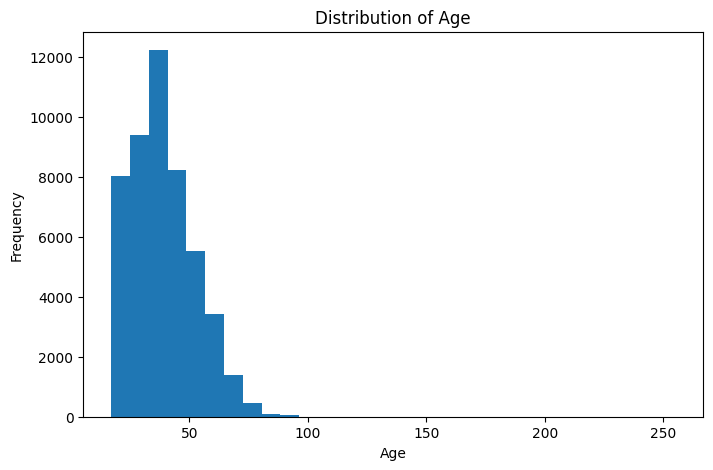

In [12]:
# Step 9.1: Age Distribution

plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=30)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

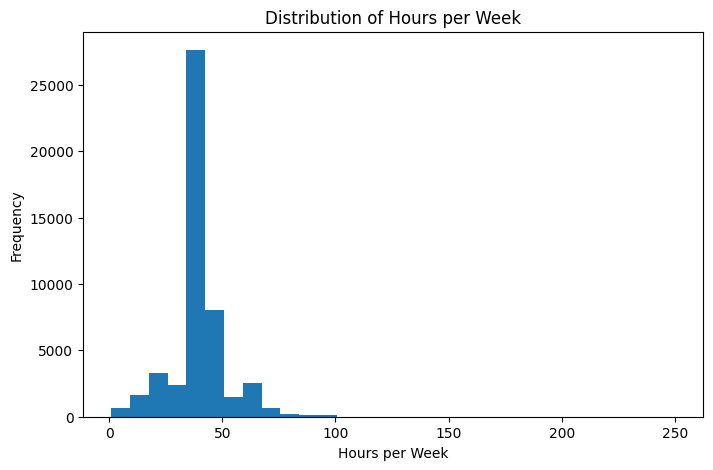

In [13]:
# Step 9.2: Hours-per-Week Distribution

plt.figure(figsize=(8, 5))
plt.hist(df['hours-per-week'], bins=30)
plt.title('Distribution of Hours per Week')
plt.xlabel('Hours per Week')
plt.ylabel('Frequency')
plt.show()

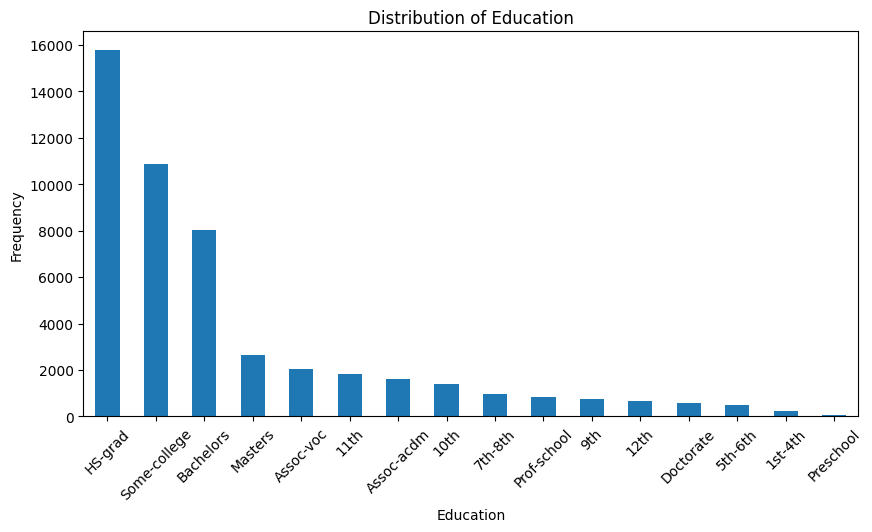

In [14]:
plt.figure(figsize=(10, 5))

df['education'].value_counts().plot(kind='bar')

plt.title('Distribution of Education')
plt.xlabel('Education')
plt.ylabel('Frequency')
plt.xticks(rotation=45)

plt.show()

In [15]:
print("Capital Gain Skewness:", df['capital-gain'].skew())
print("Capital Loss Skewness:", df['capital-loss'].skew())

Capital Gain Skewness: 11.894658996587946
Capital Loss Skewness: 4.569808857738485


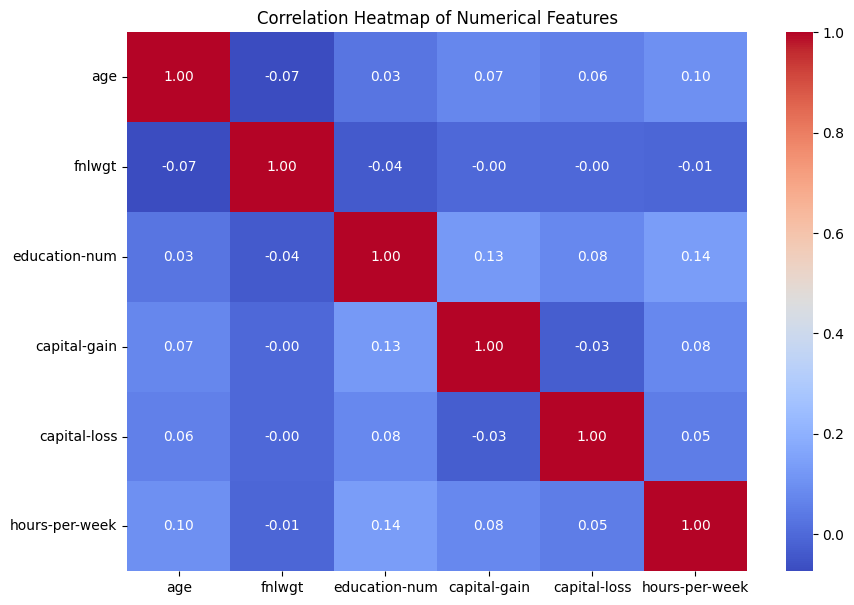

In [16]:
plt.figure(figsize=(10, 7))

correlation = df[['age',
                  'fnlwgt',
                  'education-num',
                  'capital-gain',
                  'capital-loss',
                  'hours-per-week']].corr()

sns.heatmap(correlation,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [18]:
X = scaler.fit_transform(df_encoded)

In [19]:
print("Shape of X:", X.shape)

Shape of X: (48842, 100)


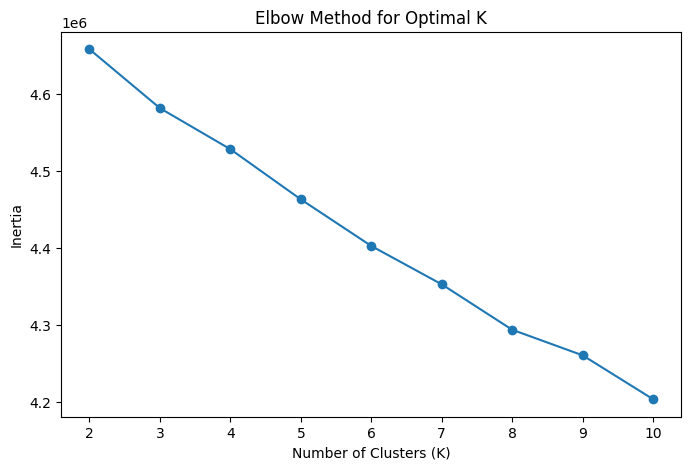

In [20]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.show()

In [22]:
silhouette_scores = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)

    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

    print("K =", k, "Silhouette Score =", score)

K = 2 Silhouette Score = 0.0489853876090096
K = 3 Silhouette Score = 0.04253525604884974
K = 4 Silhouette Score = 0.03834203161290695
K = 5 Silhouette Score = 0.031396657321976225
K = 6 Silhouette Score = 0.027375352864255888


In [23]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X)

print("K-Means clustering completed.")
print("Number of clusters:", len(set(kmeans_labels)))
print("Cluster labels:", set(kmeans_labels))

K-Means clustering completed.
Number of clusters: 2
Cluster labels: {np.int32(0), np.int32(1)}


In [24]:
print(set(kmeans_labels))
print(pd.Series(kmeans_labels).value_counts())

{np.int32(0), np.int32(1)}
0    25711
1    23131
Name: count, dtype: int64


In [25]:
df_clustered = df.copy()

df_clustered['KMeans_Cluster'] = kmeans_labels

print(df_clustered[['age', 'education', 'occupation', 'hours-per-week', 'KMeans_Cluster']].head())

    age  education         occupation  hours-per-week  KMeans_Cluster
0  39.0  Bachelors       Adm-clerical            40.0               0
1  50.0  Bachelors    Exec-managerial            13.0               1
2  38.0    HS-grad  Handlers-cleaners            40.0               0
3  53.0       11th  Handlers-cleaners            40.0               1
4  28.0  Bachelors     Prof-specialty            40.0               1


In [26]:
cluster_summary = df_clustered.groupby('KMeans_Cluster')[
    ['age', 'fnlwgt', 'education-num',
     'capital-gain', 'capital-loss', 'hours-per-week']
].mean()

print(cluster_summary)

                      age         fnlwgt  education-num  capital-gain  \
KMeans_Cluster                                                          
0               34.330248  192724.012135       9.821905    424.215550   
1               43.335783  186262.962518      10.362846   1806.961005   

                capital-loss  hours-per-week  
KMeans_Cluster                                
0                  57.855120       37.706235  
1                 120.456314       43.449483  


In [2]:
agglo = AgglomerativeClustering(n_clusters=2)

agglo_labels = agglo.fit_predict(X)

print("Agglomerative clustering completed.")
print("Cluster labels:", set(agglo_labels))

NameError: name 'AgglomerativeClustering' is not defined

In [3]:
from sklearn.cluster import AgglomerativeClustering

print("AgglomerativeClustering imported successfully.")

AgglomerativeClustering imported successfully.


In [9]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/adult_dataset.csv')

print("Dataset Shape:", df.shape)

Dataset Shape: (48842, 15)


In [10]:
df['age'] = df['age'].fillna(df['age'].median())
df['hours-per-week'] = df['hours-per-week'].fillna(df['hours-per-week'].median())

df['workclass'] = df['workclass'].fillna(df['workclass'].mode()[0])
df['occupation'] = df['occupation'].fillna(df['occupation'].mode()[0])
df['native-country'] = df['native-country'].fillna(df['native-country'].mode()[0])

print("Missing values handled.")

Missing values handled.


In [11]:
df_model = df.drop(columns=['income'])

print("Shape for clustering:", df_model.shape)

Shape for clustering: (48842, 14)


In [12]:
categorical_columns = df_model.select_dtypes(include=['object']).columns

df_encoded = pd.get_dummies(
    df_model,
    columns=categorical_columns,
    drop_first=True
)

print("Encoded shape:", df_encoded.shape)

Encoded shape: (48842, 100)


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df_encoded)

print("X shape:", X.shape)

X shape: (48842, 100)


In [14]:
import numpy as np
import gc

gc.collect()

sample_size = 5000

sample_indices = np.random.RandomState(42).choice(
    len(X),
    size=sample_size,
    replace=False
)

X_sample = X[sample_indices]

print("Sample shape:", X_sample.shape)

Sample shape: (5000, 100)


In [15]:
from sklearn.cluster import AgglomerativeClustering

agglo = AgglomerativeClustering(n_clusters=2)

agglo_labels = agglo.fit_predict(X_sample)

print("Agglomerative clustering completed.")
print("Cluster labels:", set(agglo_labels))

Agglomerative clustering completed.
Cluster labels: {np.int64(0), np.int64(1)}


In [16]:
print(pd.Series(agglo_labels).value_counts().sort_index())

0    4995
1       5
Name: count, dtype: int64


In [17]:
print(pd.Series(agglo_labels).value_counts().sort_index())

0    4995
1       5
Name: count, dtype: int64


In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("PCA shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

PCA shape: (48842, 2)
Explained variance ratio: [0.03399762 0.02686286]
Total explained variance: 0.06086048038908224


In [21]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

print("K-Means labels recreated.")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means labels recreated.
0    25721
1    23121
Name: count, dtype: int64


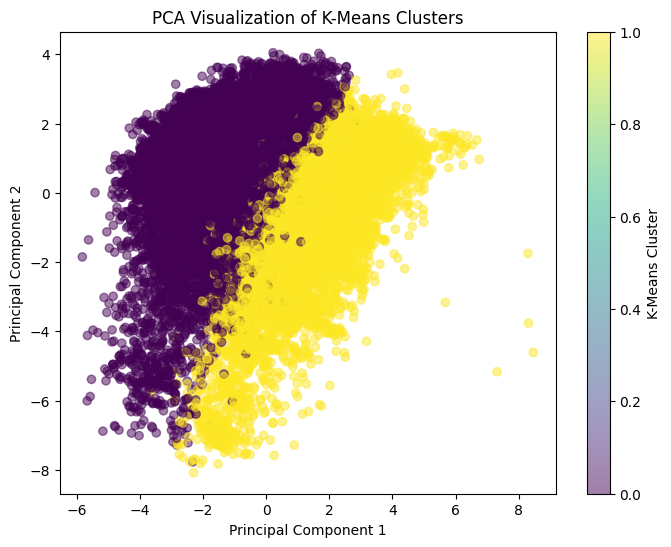

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    alpha=0.5
)

plt.title('PCA Visualization of K-Means Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='K-Means Cluster')

plt.show()

In [23]:
pca_sample = PCA(n_components=2)

X_sample_pca = pca_sample.fit_transform(X_sample)

print("Sample PCA shape:", X_sample_pca.shape)

Sample PCA shape: (5000, 2)


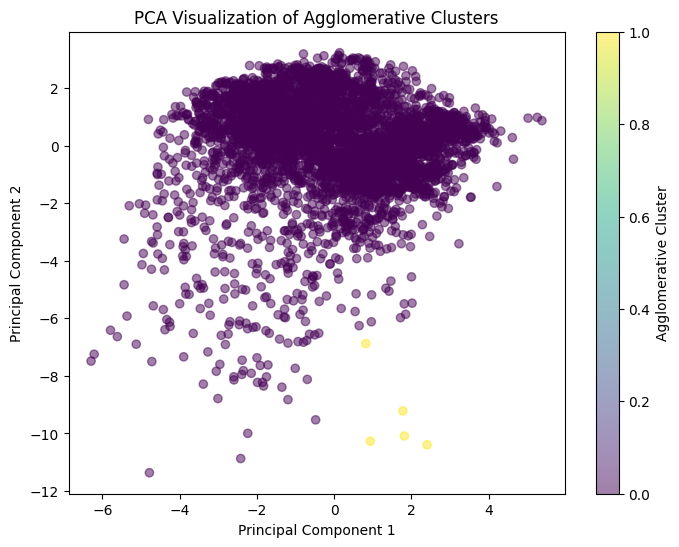

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_sample_pca[:, 0],
    X_sample_pca[:, 1],
    c=agglo_labels,
    alpha=0.5
)

plt.title('PCA Visualization of Agglomerative Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Agglomerative Cluster')

plt.show()